# Viagens a Serviço do Governo Federal
## Análise de gastos e deslocamentos — janeiro a junho de 2025

**Projeto Avaliativo · Módulo 1**

As três primeiras perguntas consultam a Silver. As quatro seguintes usam
indicadores Gold no PostgreSQL. As consultas usam todo o recorte recebido,
com as regras de limpeza descritas no README. Os resultados descrevem o
semestre analisado.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

from banco import CHAVE_PIPELINE, conectar, executar

plt.style.use("seaborn-v0_8-whitegrid")


def consultar(conexao, comando, parametros=None):
    with executar(conexao, comando, parametros) as cursor:
        nomes = [coluna.name for coluna in cursor.description]
        return pd.DataFrame(cursor.fetchall(), columns=nomes)


def brl(valor):
    if pd.isna(valor):
        return "—"
    return f"R$ {float(valor):,.2f}".replace(",", "_").replace(".", ",").replace("_", ".")


def barras(dados, categoria, medida, titulo, eixo_x, eixo_y, moeda=False,
           legenda=None, ordenado=True):
    quadro = dados.sort_values(medida) if ordenado else dados
    valores = quadro[medida].astype(float)
    fig, ax = plt.subplots(figsize=(10, max(3.5, 2 + 0.50 * len(quadro))))
    barras_plotadas = ax.barh(
        quadro[categoria], valores, color="#25638D", label=legenda or eixo_x
    )
    if valores.eq(0).all() and len(valores):
        ax.set_xlim(0, 1)
        ax.bar_label(barras_plotadas, labels=[brl(0)] * len(valores), padding=4)
    ax.set(title=titulo, xlabel=eixo_x, ylabel=eixo_y)
    if moeda and valores.abs().max() >= 10_000_000:
        ax.set_xlabel(f"{eixo_x} — em milhões")
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:.0f}"))
    else:
        ax.xaxis.set_major_formatter(
            FuncFormatter(
                lambda x, _: brl(x) if moeda else f"{x:,.0f}".replace(",", ".")
            )
        )
    ax.legend(loc="upper right", bbox_to_anchor=(1, -0.18), frameon=False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def mostrar(dados, monetarias=()):
    formatado = dados.copy()
    for coluna in monetarias:
        formatado[coluna] = formatado[coluna].map(brl)
    display(formatado)

## 1. Quais são os cinco órgãos com maior custo total?

O custo líquido vem de `silver_viagem.valor_total`. O agrupamento usa o código
e o nome do órgão superior.

,cod_orgao_superior,orgao,viagens,custo_total
0,30000,Ministério da Justiça e Segurança Pública,75742,"R$ 486.933.121,65"
1,52000,Ministério da Defesa,61912,"R$ 156.070.304,49"
2,26000,Ministério da Educação,65295,"R$ 111.291.349,34"
3,44000,Ministério do Meio Ambiente e Mudança do Clima,19413,"R$ 49.697.710,16"
4,33000,Ministério da Previdência Social,8190,"R$ 40.417.309,06"


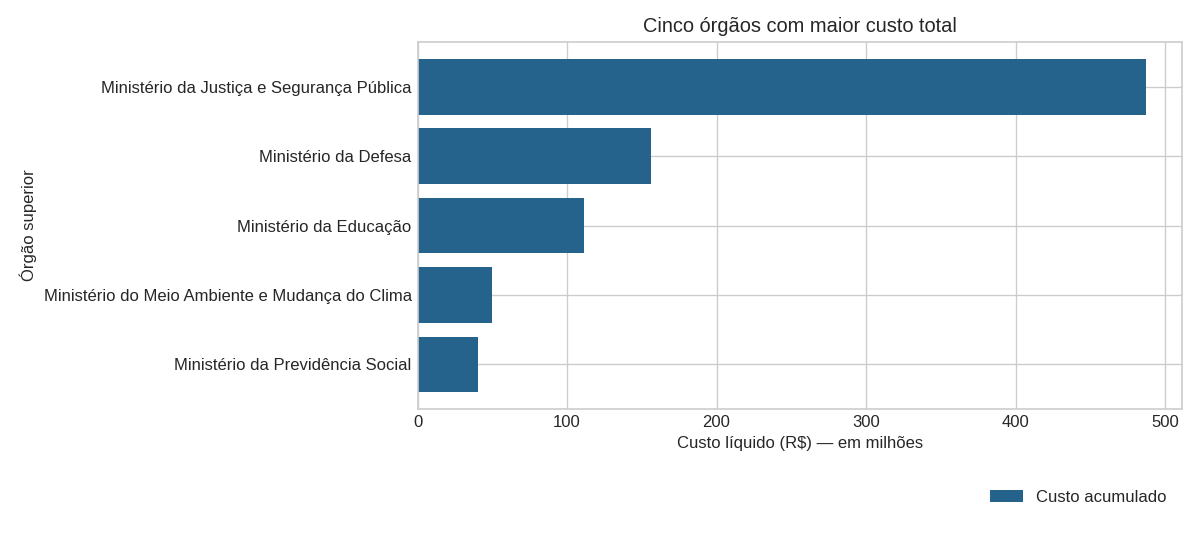

**Ministério da Justiça e Segurança Pública** lidera com **R$ 486.933.121,65** em 75742 viagens com custo registrado.

In [2]:
with conectar() as conexao:
    orgaos = consultar(conexao, '''
        SELECT cod_orgao_superior, nome_orgao_superior AS orgao,
               count(valor_total) AS viagens, sum(valor_total) AS custo_total
        FROM silver_viagem
        WHERE valor_total IS NOT NULL
        GROUP BY cod_orgao_superior, nome_orgao_superior
        ORDER BY custo_total DESC, orgao, cod_orgao_superior
        LIMIT 5
    ''')

mostrar(orgaos, ("custo_total",))
barras(orgaos, "orgao", "custo_total", "Cinco órgãos com maior custo total",
       "Custo líquido (R$)", "Órgão superior", moeda=True, legenda="Custo acumulado")
lider = orgaos.iloc[0]
display(Markdown(
    f"**{lider.orgao}** lidera com **{brl(lider.custo_total)}** "
    f"em {lider.viagens} viagens com custo registrado."
))

## 2. Quais são os três destinos com maior custo médio por viagem?

O campo `destinos` é separado pela vírgula. A análise inclui os rótulos
no formato cidade/UF ou cidade/país. Rótulos incompletos, como “Brasí”,
ficam fora do ranking. Cada par viagem–destino conta uma vez. Para viagens com vários destinos, a média de
cada destino inclui o custo integral da viagem associada. Assim, o indicador
mede o custo médio das viagens que incluíram cada destino. A tabela mostra
o número de viagens por destino para dar contexto a médias com poucas observações.

,destino,viagens,custo_medio
0,Sananduva/RS,93,"R$ 87.164,61"
1,Monte Negro/RO,96,"R$ 86.612,71"
2,Livingstone/Zâmbia,2,"R$ 86.452,66"


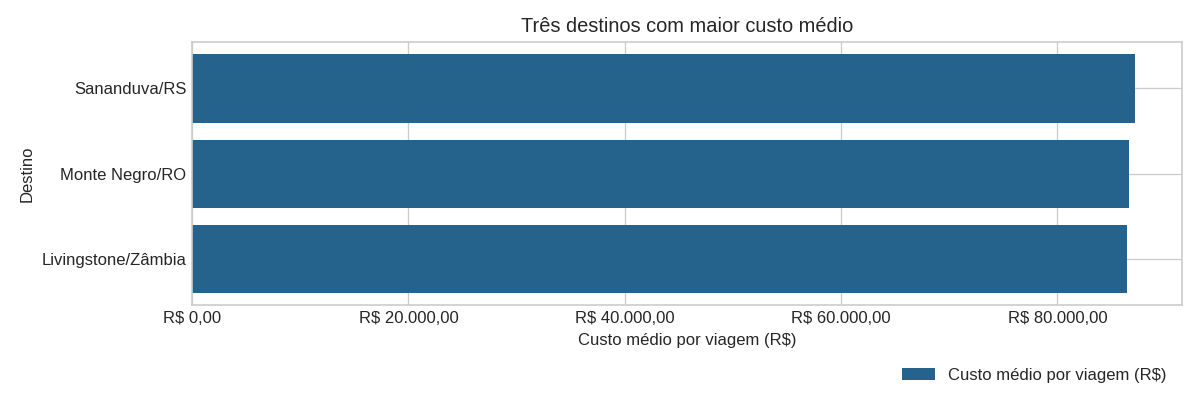

**Sananduva/RS** tem a maior média, **R$ 87.164,61**, calculada com 93 viagem(ns). O tamanho da amostra é importante ao comparar esse valor com outros destinos.

In [3]:
with conectar() as conexao:
    destinos = consultar(conexao, r'''
        WITH viagem_destino AS (
            SELECT DISTINCT v.id_viagem, btrim(d.nome) AS destino, v.valor_total
            FROM silver_viagem AS v
            CROSS JOIN LATERAL regexp_split_to_table(v.destinos, ',')
                AS d(nome)
            WHERE v.valor_total IS NOT NULL
              AND btrim(d.nome) ~ '^[^/]+/[^/[:digit:],]{2,}$'
        )
        SELECT destino, count(*) AS viagens, avg(valor_total) AS custo_medio
        FROM viagem_destino
        GROUP BY destino
        ORDER BY custo_medio DESC, destino
        LIMIT 3
    ''')

mostrar(destinos, ("custo_medio",))
barras(destinos, "destino", "custo_medio", "Três destinos com maior custo médio",
       "Custo médio por viagem (R$)", "Destino", moeda=True)
lider = destinos.iloc[0]
display(Markdown(
    f"**{lider.destino}** tem a maior média, **{brl(lider.custo_medio)}**, "
    f"calculada com {lider.viagens} viagem(ns). O tamanho da amostra é importante "
    "ao comparar esse valor com outros destinos."
))

## 3. Qual é a viagem de maior duração e qual foi seu custo total?

A duração é a diferença em dias entre as datas final e inicial. Uma viagem
que começa e termina no mesmo dia tem duração zero por essa convenção.
Em caso de empate, a consulta seleciona o menor identificador.
O gráfico separa os componentes do custo e representa a devolução com sinal negativo.

,id_viagem,orgao,data_inicio,data_fim,duracao_dias,valor_diarias,valor_passagens,valor_outros_gastos,valor_devolucao,valor_total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,383,"R$ 0,00","R$ 0,00","R$ 0,00","R$ 0,00","R$ 0,00"


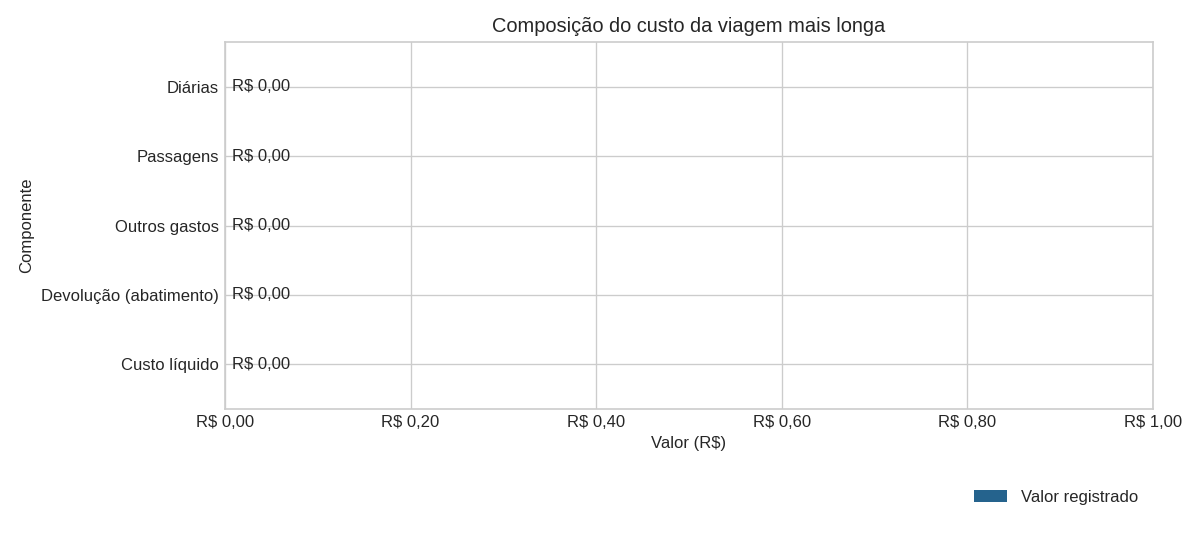

A viagem **0000000000020699856** durou **383 dias** e teve custo líquido de **R$ 0,00**. O gráfico mostra quanto cada componente representa no cálculo.

In [4]:
with conectar() as conexao:
    longa = consultar(conexao, '''
        SELECT id_viagem, nome_orgao_superior AS orgao, data_inicio, data_fim,
               duracao_dias, valor_diarias, valor_passagens, valor_outros_gastos,
               valor_devolucao, valor_total
        FROM silver_viagem
        WHERE duracao_dias IS NOT NULL
        ORDER BY duracao_dias DESC, id_viagem
        LIMIT 1
    ''')

mostrar(longa, (
    "valor_diarias", "valor_passagens", "valor_outros_gastos",
    "valor_devolucao", "valor_total"
))
viagem = longa.iloc[0]
componentes = pd.DataFrame({
    "componente": ["Custo líquido", "Devolução (abatimento)", "Outros gastos",
                   "Passagens", "Diárias"],
    "valor": [viagem.valor_total, -(viagem.valor_devolucao or 0), viagem.valor_outros_gastos,
              viagem.valor_passagens, viagem.valor_diarias],
}).fillna({"valor": 0})
barras(componentes, "componente", "valor", "Composição do custo da viagem mais longa",
       "Valor (R$)", "Componente", moeda=True, legenda="Valor registrado",
       ordenado=False)
display(Markdown(
    f"A viagem **{viagem.id_viagem}** durou **{viagem.duracao_dias} dias** "
    f"e teve custo líquido de **{brl(viagem.valor_total)}**. "
    "O gráfico mostra quanto cada componente representa no cálculo."
))

## Gold agregada no PostgreSQL

O SQL cria a view `vw_gold_indicadores` com quatro agregações e atualiza a
tabela `gold_indicadores` com o mesmo resultado. Cada agregação usa
`JOIN` com viagens e `GROUP BY` na categoria. A view reflete a Silver
atual. A tabela contém a fotografia da última execução desta célula.

In [5]:
with conectar() as conexao:
    executar(conexao, "SELECT pg_advisory_xact_lock(%s)", (CHAVE_PIPELINE,))
    executar(conexao, Path("sql/3_gold.sql").read_text(encoding="utf-8"))
    resumo = consultar(conexao, '''
        SELECT indicador, count(*) AS categorias
        FROM gold_indicadores
        GROUP BY indicador
        ORDER BY indicador
    ''')

display(resumo)

,indicador,categorias
0,pagamento_por_orgao,216
1,pagamento_por_tipo,4
2,transporte_por_trecho,7
3,uf_destino_por_trecho,27


## 4. Qual tipo de pagamento tem o maior valor médio?

A média usa os registros de pagamento com valor preenchido. A quantidade
de pagamentos ajuda a contextualizar o resultado de cada categoria.

,tipo,quantidade,valor_medio
0,PASSAGEM,186008,"R$ 1.856,78"
1,DIÁRIAS,366351,"R$ 1.797,55"
2,Serviço correlato: seguro,4882,"R$ 447,72"
3,RESTITUIÇÃO,11570,"R$ 245,69"


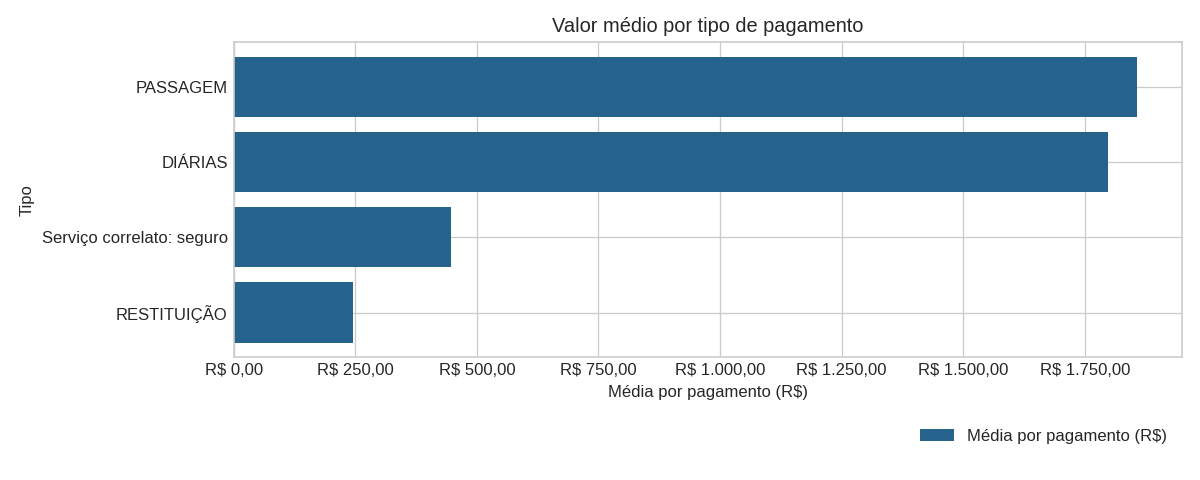

**PASSAGEM** tem a maior média, **R$ 1.856,78**, em 186008 pagamentos.

In [6]:
with conectar() as conexao:
    tipos = consultar(conexao, '''
        SELECT categoria AS tipo, quantidade, media AS valor_medio
        FROM gold_indicadores
        WHERE indicador = 'pagamento_por_tipo'
        ORDER BY valor_medio DESC, tipo
    ''')

mostrar(tipos, ("valor_medio",))
barras(tipos, "tipo", "valor_medio", "Valor médio por tipo de pagamento",
       "Média por pagamento (R$)", "Tipo", moeda=True)
lider = tipos.iloc[0]
display(Markdown(
    f"**{lider.tipo}** tem a maior média, **{brl(lider.valor_medio)}**, "
    f"em {lider.quantidade} pagamentos."
))

## 5. Qual meio de transporte é mais usado nos trechos?

Cada trecho com transporte válido conta uma vez. A categoria “Inválido”
e os campos vazios ficam fora deste ranking.

,transporte,trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Fluvial,8429
5,Ferroviário,874
6,Marítimo,481


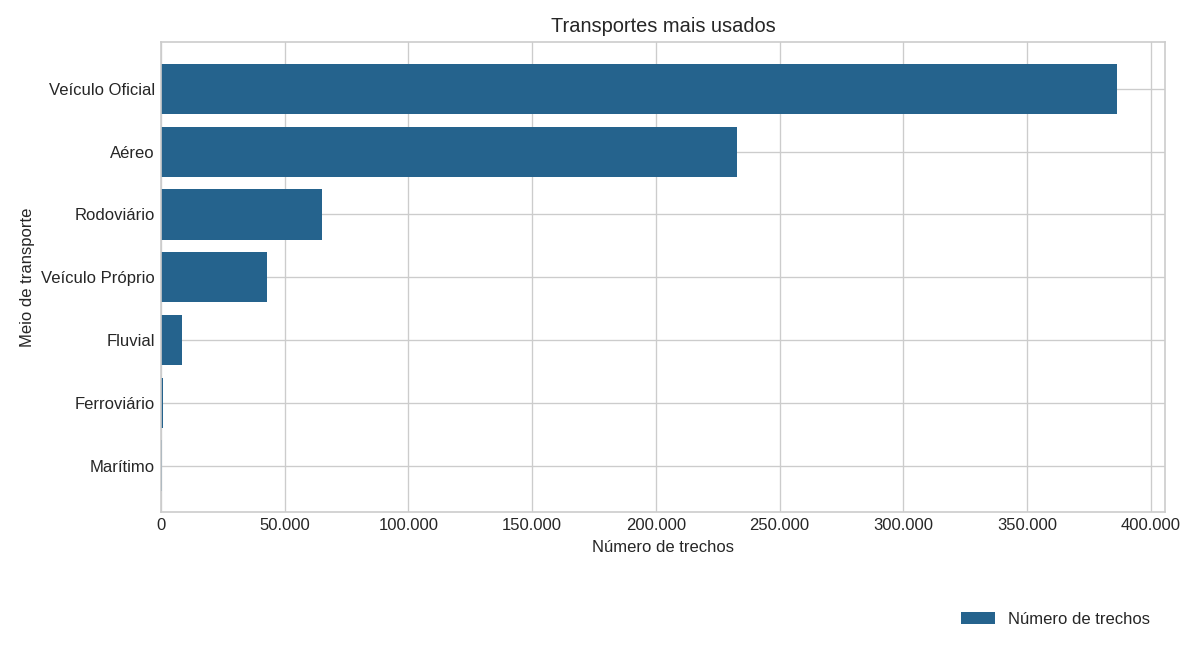

**Veículo Oficial** lidera com **386424 trechos**, 52.5% dos trechos com transporte válido.

In [7]:
with conectar() as conexao:
    transportes = consultar(conexao, '''
        SELECT categoria AS transporte, quantidade AS trechos
        FROM gold_indicadores
        WHERE indicador = 'transporte_por_trecho'
        ORDER BY trechos DESC, transporte
    ''')

mostrar(transportes)
barras(transportes.head(10), "transporte", "trechos", "Transportes mais usados",
       "Número de trechos", "Meio de transporte")
lider = transportes.iloc[0]
participacao = lider.trechos / transportes.trechos.sum()
display(Markdown(
    f"**{lider.transporte}** lidera com **{lider.trechos} trechos**, "
    f"{participacao:.1%} dos trechos com transporte válido."
))

## 6. Qual UF de destino aparece em mais trechos?

A análise considera as 27 UFs brasileiras. O gráfico mostra as dez primeiras,
e a tabela contém todo o ranking.

,uf,trechos
0,SP,82722
1,DF,79962
2,MG,50965
3,RJ,44197
4,PR,42603
5,PA,40044
6,RS,38684
7,MS,30516
8,BA,28375
9,PE,28372


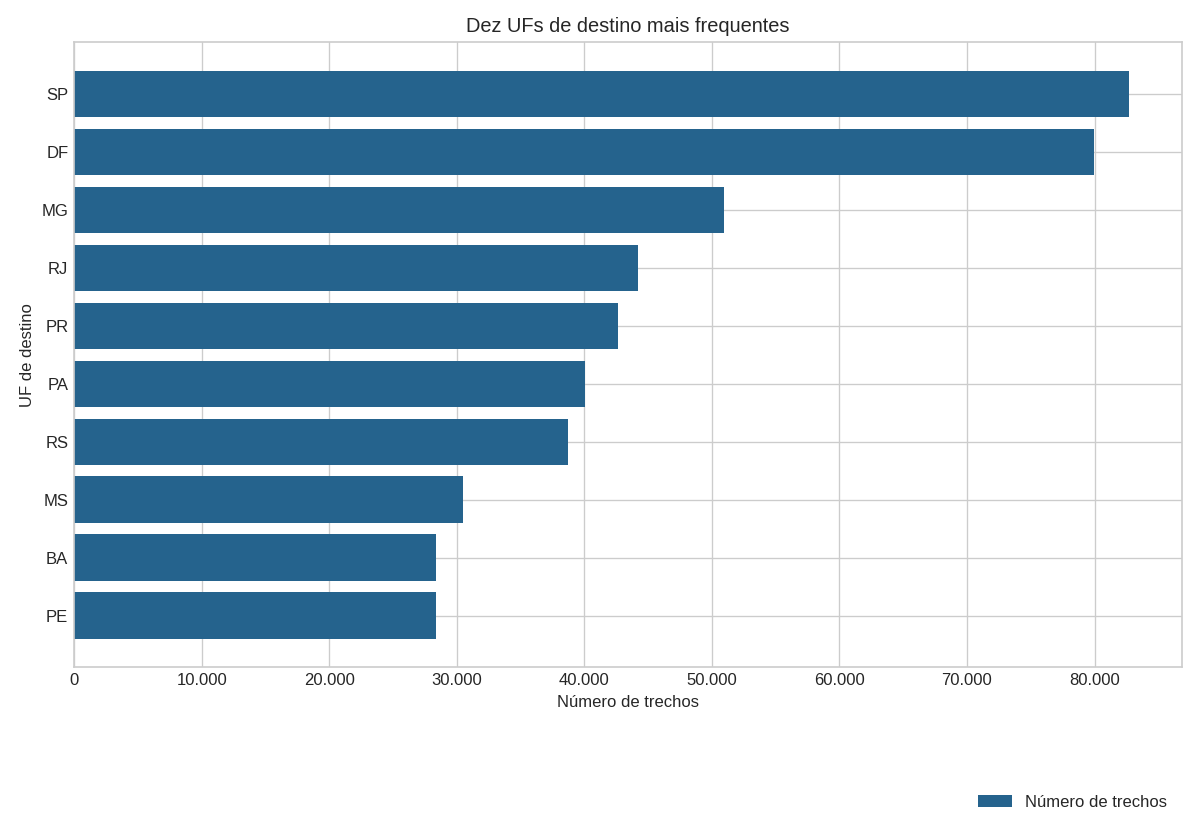

**SP** lidera com **82722 trechos**, 11.1% dos trechos com destino em uma UF brasileira.

In [8]:
with conectar() as conexao:
    ufs = consultar(conexao, '''
        SELECT categoria AS uf, quantidade AS trechos
        FROM gold_indicadores
        WHERE indicador = 'uf_destino_por_trecho'
        ORDER BY trechos DESC, uf
    ''')

mostrar(ufs)
barras(ufs.head(10), "uf", "trechos", "Dez UFs de destino mais frequentes",
       "Número de trechos", "UF de destino")
lider = ufs.iloc[0]
participacao = lider.trechos / ufs.trechos.sum()
display(Markdown(
    f"**{lider.uf}** lidera com **{lider.trechos} trechos**, "
    f"{participacao:.1%} dos trechos com destino em uma UF brasileira."
))

## 7. Qual órgão pagou mais no total?

A soma usa os valores na tabela de pagamentos agrupados pelo órgão pagador.
A tabela mostra os cinco primeiros. Quando a fonte registra “Sigiloso”,
esse valor é mantido como categoria, e o maior total entre os órgãos
identificados é apresentado separadamente.

In [9]:
with conectar() as conexao:
    pagadores = consultar(conexao, '''
        SELECT categoria AS orgao_pagador, quantidade AS pagamentos, total
        FROM gold_indicadores
        WHERE indicador = 'pagamento_por_orgao'
        ORDER BY total DESC, orgao_pagador
        LIMIT 5
    ''')

mostrar(pagadores, ("total",))
lider = pagadores.iloc[0]
identificados = pagadores[pagadores.orgao_pagador.str.casefold() != "sigiloso"]
display(Markdown(
    f"A categoria **{lider.orgao_pagador}** registra o maior total, "
    f"**{brl(lider.total)}**, em {lider.pagamentos} pagamentos."
))
if not identificados.empty and lider.orgao_pagador.casefold() == "sigiloso":
    identificado = identificados.iloc[0]
    display(Markdown(
        f"Entre os órgãos identificados, **{identificado.orgao_pagador}** "
        f"lidera com **{brl(identificado.total)}**."
    ))

,orgao_pagador,pagamentos,total
0,Sigiloso,86878,"R$ 170.659.883,35"
1,Fundo Nacional de Segurança Pública,53440,"R$ 141.911.719,64"
2,Comando da Aeronáutica,45962,"R$ 81.180.823,06"
3,Comando do Exército,22056,"R$ 35.901.379,45"
4,Instituto Nacional do Seguro Social,17899,"R$ 35.385.354,57"


A categoria **Sigiloso** registra o maior total, **R$ 170.659.883,35**, em 86878 pagamentos.

Entre os órgãos identificados, **Fundo Nacional de Segurança Pública** lidera com **R$ 141.911.719,64**.

## Conclusão

Os rankings separam custo líquido da viagem, gasto registrado pelo órgão
pagador e frequência de deslocamento. Cada medida responde a uma pergunta
diferente. As médias por destino devem ser lidas com o número de viagens,
e as participações por transporte e UF usam apenas os trechos com informação
válida para o indicador.